# 50. 장기 기상 자료와 특보 이력: 기후 위기 정의, 특보 기준 민감도, 기후 시나리오 손실

입력: `06_weather_long.py`(ASOS 일자료 1991~2025, 서울 108·춘천 101)와 `07_warnings.py`(기상특보 발령 이력 2005~2025)의 출력.

1. 1991~2025 추세: 폭염·열대야·집중호우 일수, 강수 강도가 과거보다 늘었는가(회의 질문 "과거와 무엇이 달라졌나")
2. 2025년 7~12월이 평년(1991~2020) 대비 얼마나 이례적인가(기상청 이상기후 정의: 평년 상·하위 10%)
3. 특보 통계와 우리 기준의 비교, 특보·이상고온 기준으로 민감도 재추정
4. 기후 시나리오 손실: 평년·최근 10년·추세 연장(2035)에서 7~12월 예상 손실

출력: `outputs/tables/l_*.csv`, 그림 `l*.png`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path.cwd()))
from common import (FIG, TAB, REGIONS, REGION_NAME, FACE_GROUPS, load)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, EVENT_COLOR, run_series, pool, pct, finish)

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 80)

long = load("weather_long_daily")
ann = load("weather_annual")
clim = load("weather_climatology")
ctx = load("weather_2025_context")
wd = load("warnings_daily"); wa = load("warnings_annual")
prof = load("industry_profile")
panel = load("model_panel_day"); scope = panel[panel.in_scope == 1].copy()
scope.loc[scope.sales == 0, "y"] = np.nan
perday = pd.read_csv(TAB / "v_perday.csv", encoding="utf-8-sig")
NORMAL = (1991, 2020)
print("장기 자료", long.date.min().date(), "~", long.date.max().date(), "| 특보", wd.date.min().date(), "~", wd.date.max().date())

장기 자료 1991-01-01 ~ 2025-12-31 | 특보 2005-07-01 ~ 2025-12-31


## 1. 1991~2025 추세: 무엇이 달라졌나

연간 통계(ASOS 공식 일자료). 선형 추세의 10년당 변화량과 p값, 평년(1991~2020) 평균, 2025년 값과 35년 중 순위를 표로 낸다.

In [2]:
IND = {"heat33_days": "폭염일(일최고 33℃+)", "heat35_days": "35℃+ 일", "tropical_days": "열대야(일최저 25℃+)", "summer_ta_mean": "여름(6~8월) 평균기온",
       "rain50_days": "일 50mm+ 일수", "rain80_days": "일 80mm+ 일수", "rain_1h30_days": "1시간 30mm+ 일수", "rain_days": "강수일수(1mm+)",
       "precip_total": "연 강수량(mm)", "precip_intensity": "강수강도(mm/강수일)", "rn_max_1h": "연 최대 1시간 강수", "cold12_days": "한파일(일최저 −12℃ 이하)"}
a = ann[ann.window == "연간"].copy()
rows = []
for region, g in a.groupby("region"):
    g = g.sort_values("year")
    for k, name in IND.items():
        s = g.set_index("year")[k].dropna()
        slope, icpt, r, p, se = stats.linregress(s.index, s.values)
        rows.append({"region": region, "지표": name, "평년 평균": s.loc[NORMAL[0]:NORMAL[1]].mean(), "최근 10년(2016~25)": s.loc[2016:2025].mean(),
                     "2025": s.get(2025, np.nan), "2025 순위(1=최대)": int((s > s.get(2025, np.nan)).sum() + 1), "10년당 변화": slope * 10, "p": p})
trend = pd.DataFrame(rows)
trend.round(2).to_csv(TAB / "l_trend.csv", index=False, encoding="utf-8-sig")
trend.pivot(index="지표", columns="region", values=["평년 평균", "최근 10년(2016~25)", "2025", "2025 순위(1=최대)", "10년당 변화", "p"]).round(2)

평년 평균          최근 10년(2016~25)               2025          2025 순위(1=최대)           10년당 변화                 p        
region           chuncheon  gangnam       chuncheon  gangnam chuncheon  gangnam     chuncheon gangnam chuncheon gangnam chuncheon gangnam
지표                                                                                                                                       
1시간 30mm+ 일수          2.00     3.23            2.00     3.00      2.00     5.00          13.0     5.0      0.21    0.00      0.37    0.99
35℃+ 일                2.73     2.63            6.10     7.50     11.00    13.00           2.0     3.0      1.28    1.86      0.07    0.03
강수강도(mm/강수일)         17.10    17.83           18.10    17.14     19.07    18.84           9.0    14.0      0.43   -0.42      0.45    0.50
강수일수(1mm+)           78.37    79.23           73.90    78.40     77.00    84.00          18.0     8.0     -1.04    0.45      0.54    0.77
여름(6~8월) 평균기온        24.04    24.73           25.09    25.89     25.81    27.05           1.0     1.0      0.63    0.62      0.00    0.00
연 강수량(mm)          1341.28  1417.98         1327.86  1350.58   1468.30  1582.40          11.0    12.0     12.58  -23.05      0.81    0.70
연 최대 1시간 강수          41.78    50.43           41.71    46.37     46.60    41.20          10.0    26.0      1.16   -2.45      0.49    0.34
열대야(일최저 25℃+)         3.00    10.97            9.20    25.00      5.00    45.00           9.0     1.0      2.62    6.19      0.00    0.00
일 50mm+ 일수            6.37     6.97            6.00     7.00      8.00     8.00           8.0    10.0      0.13    0.03      0.77    0.94
일 80mm+ 일수            2.70     3.20            1.90     2.60      1.00     2.00          27.0    20.0     -0.42   -0.29      0.17    0.43
폭염일(일최고 33℃+)        11.43     8.73           21.30    19.90     32.00    28.00           2.0     4.0      3.84    4.39      0.01    0.01
한파일(일최저 −12℃ 이하)     18.57     3.40           17.70     4.40     17.00     1.00          17.0    23.0      1.20    0.94      0.45    0.10

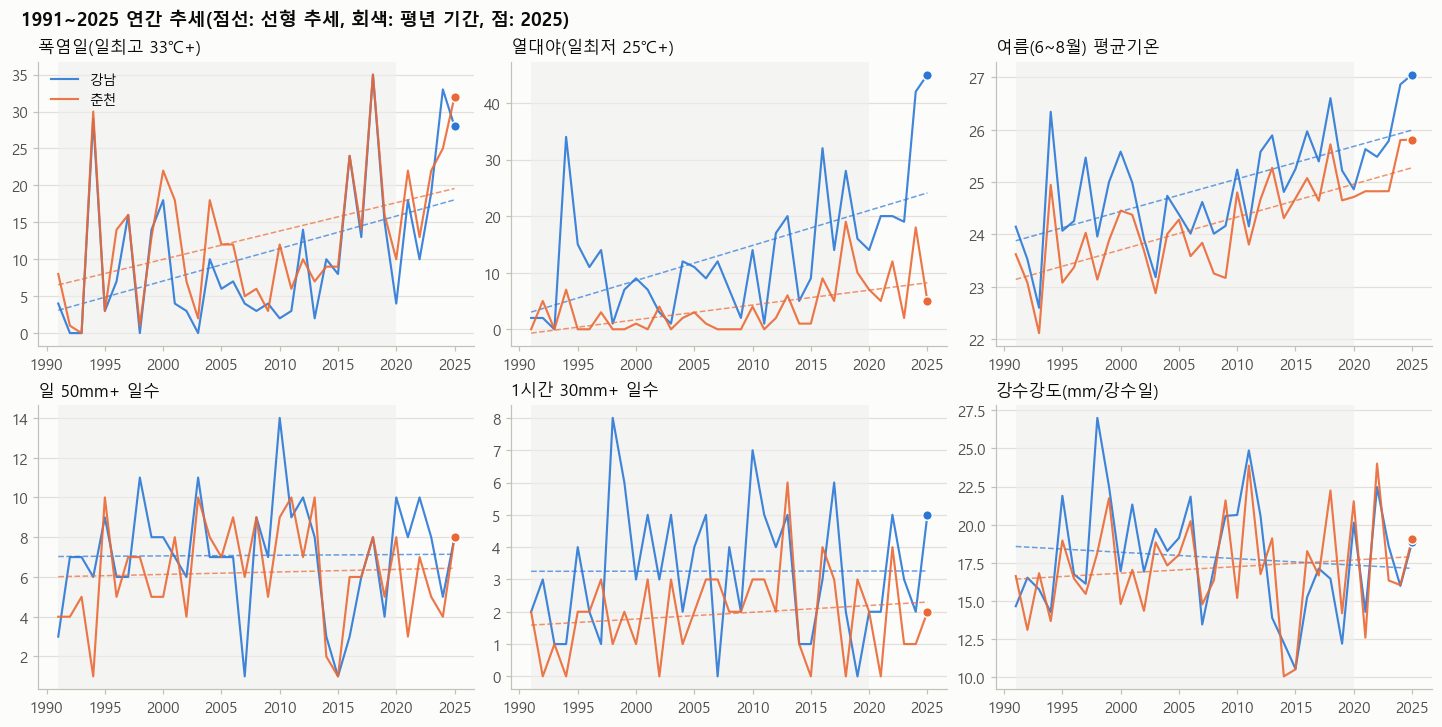

In [3]:
SHOW = ["heat33_days", "tropical_days", "summer_ta_mean", "rain50_days", "rain_1h30_days", "precip_intensity"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), layout="constrained")
for ax, k in zip(axes.flat, SHOW):
    for r in REGIONS:
        g = a[a.region == r].sort_values("year")
        ax.plot(g.year, g[k], color=REGION_COLOR[r], lw=1.4, alpha=0.9, label=REGION_NAME[r])
        s = g.set_index("year")[k].dropna()
        slope, icpt = np.polyfit(s.index, s.values, 1)
        ax.plot(s.index, icpt + slope * s.index, color=REGION_COLOR[r], lw=1, ls="--", alpha=0.7)
        ax.scatter([2025], [s.get(2025)], color=REGION_COLOR[r], s=40, zorder=5, edgecolors=SURFACE)
    ax.axvspan(NORMAL[0], NORMAL[1], color=WASH, alpha=0.6, lw=0)
    ax.set_title(IND[k]); ax.grid(axis="x", visible=False)
axes[0, 0].legend(loc="upper left")
finish(fig, FIG, "l01_trend", "1991~2025 연간 추세(점선: 선형 추세, 회색: 평년 기간, 점: 2025)")
plt.show()

## 2. 2025년 7~12월은 얼마나 이례적인가

평년(1991~2020)의 같은 시기(앞뒤 7일 창) 분포와 비교. 기상청 이상고온 정의(평년 상위 10%)로 이상고온일을 센다.

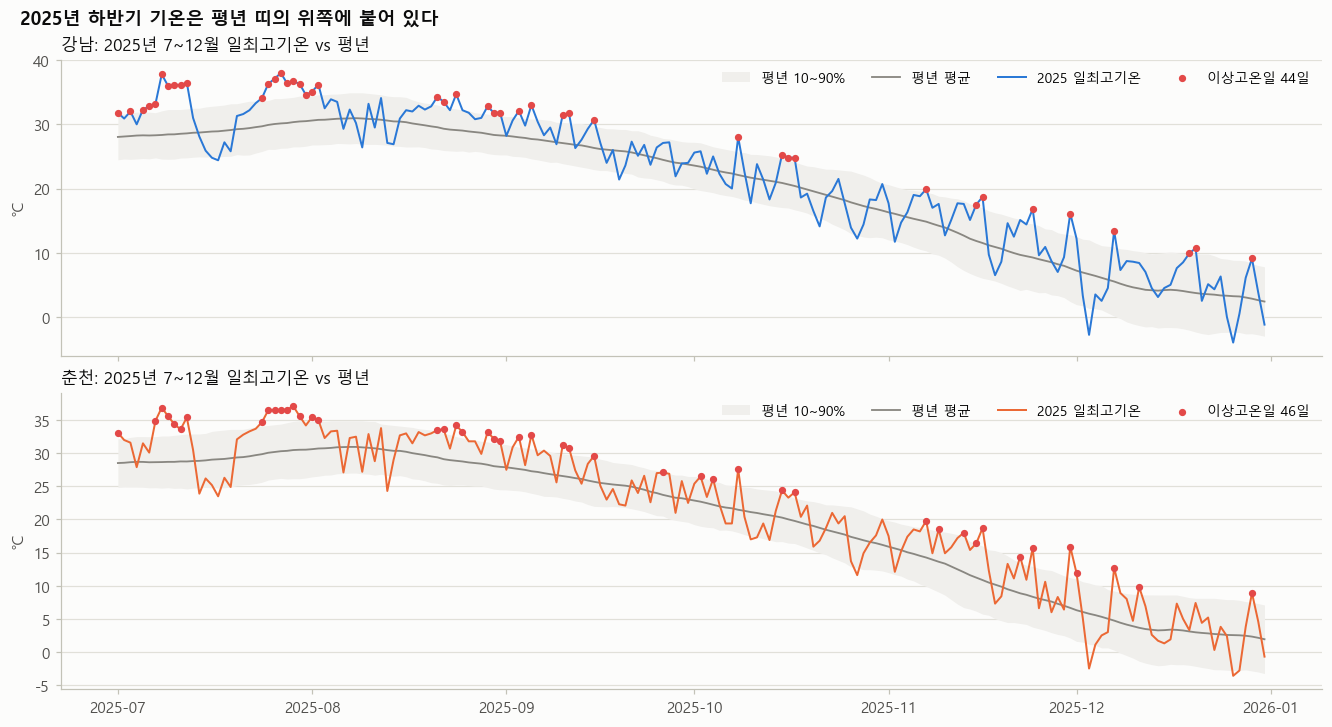

region,chuncheon,gangnam
이상고온일,46.0,44.0
이상야간고온일,44.0,61.0
극한강수일,19.0,21.0
최고기온편차,1.6,1.7
최저기온편차,1.7,2.0
7~12월 폭염일 2025,30.0,25.0
7~12월 폭염일 평년,9.8,8.1
7~12월 열대야 2025,5.0,44.0
7~12월 열대야 평년,3.0,11.0
7~12월 일10mm+ 2025,26.0,33.0


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, layout="constrained")
for ax, r in zip(axes, REGIONS):
    g = ctx[ctx.region == r].sort_values("date")
    ax.fill_between(g.date, g.ta_max_mean - (g.ta_max_p90 - g.ta_max_mean), g.ta_max_p90, color=WASH, lw=0, label="평년 10~90%")
    ax.plot(g.date, g.ta_max_mean, color=MUTED, lw=1.2, label="평년 평균")
    ax.plot(g.date, g.ta_max, color=REGION_COLOR[r], lw=1.3, label="2025 일최고기온")
    hot = g[g.hot_extreme == 1]
    ax.scatter(hot.date, hot.ta_max, color="#e34948", s=14, zorder=5, label=f"이상고온일 {len(hot)}일")
    ax.set_title(f"{REGION_NAME[r]}: 2025년 7~12월 일최고기온 vs 평년"); ax.set_ylabel("℃"); ax.legend(loc="upper right", ncol=4); ax.grid(axis="x", visible=False)
finish(fig, FIG, "l02_context2025", "2025년 하반기 기온은 평년 띠의 위쪽에 붙어 있다")
plt.show()
summ25 = ctx.groupby("region").agg(이상고온일=("hot_extreme", "sum"), 이상야간고온일=("night_extreme", "sum"), 극한강수일=("rain_extreme", "sum"),
                                  최고기온편차=("ta_max_anom", "mean"), 최저기온편차=("ta_min_anom", "mean"))
jd = ann[ann.window == "7~12월"]
for r in REGIONS:
    s = jd[jd.region == r].set_index("year")
    summ25.loc[r, "7~12월 폭염일 2025"] = s.loc[2025, "heat33_days"]; summ25.loc[r, "7~12월 폭염일 평년"] = s.loc[NORMAL[0]:NORMAL[1], "heat33_days"].mean()
    summ25.loc[r, "7~12월 열대야 2025"] = s.loc[2025, "tropical_days"]; summ25.loc[r, "7~12월 열대야 평년"] = s.loc[NORMAL[0]:NORMAL[1], "tropical_days"].mean()
    summ25.loc[r, "7~12월 일10mm+ 2025"] = s.loc[2025, "rain10_days"]; summ25.loc[r, "7~12월 일10mm+ 평년"] = s.loc[NORMAL[0]:NORMAL[1], "rain10_days"].mean()
summ25.round(1).to_csv(TAB / "l_context2025.csv", encoding="utf-8-sig")
summ25.round(1).T

## 3. 특보 이력

연도별 특보 일수(2005.7~). 폭염특보는 2008년에 시작했고 2020년부터 체감온도 기준이라 연도 비교에 제도 변화가 섞인다. 서울 권역(동남권) 세분은 최근 자료에만 있다.

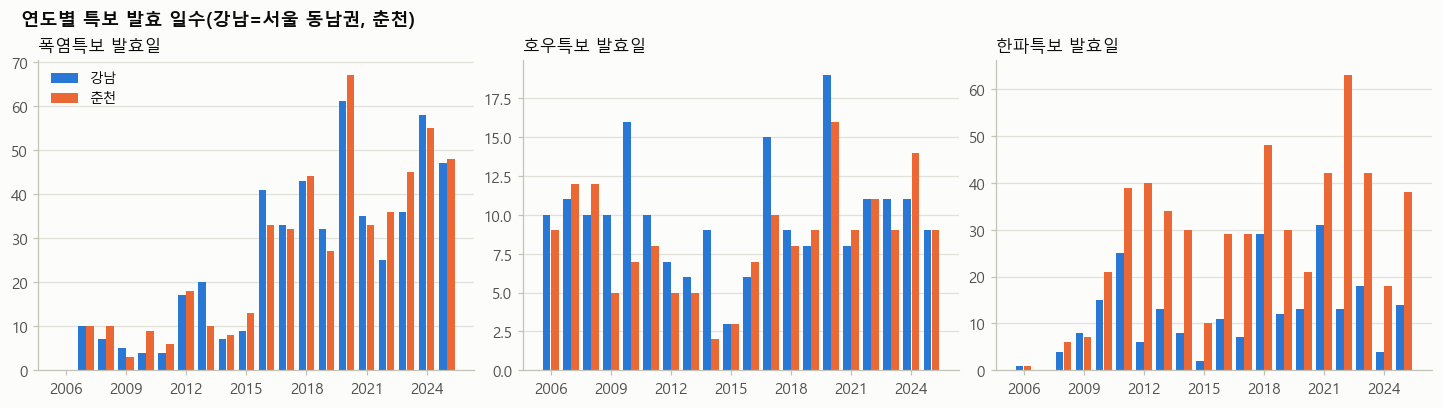

우리0_특보0  우리0_특보1  우리1_특보0  우리1_특보1
강남 폭염: 우리 기준(33℃) × 특보                     135       24        3       22
   호우: 우리 기준(영업시간 10mm) × 특보(영업시간 발효)      166        1       11        6
춘천 폭염: 우리 기준(33℃) × 특보                     137       17        1       29
   호우: 우리 기준(영업시간 10mm) × 특보(영업시간 발효)      162        1       15        6

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained")
for ax, (k, name) in zip(axes, [("wrn_heat", "폭염특보 발효일"), ("wrn_rain", "호우특보 발효일"), ("wrn_cold", "한파특보 발효일")]):
    for i, r in enumerate(REGIONS):
        g = wa[(wa.region == r) & (wa.year >= 2006) & (wa.year <= 2025)]
        ax.bar(g.year + (i - 0.5) * 0.4, g[k], width=0.38, color=REGION_COLOR[r], label=REGION_NAME[r])
    ax.set_title(name); ax.grid(axis="x", visible=False); ax.set_xticks(range(2006, 2026, 3))
axes[0].legend(loc="upper left")
finish(fig, FIG, "l03_warnings", "연도별 특보 발효 일수(강남=서울 동남권, 춘천)")
plt.show()
w25 = wd[(wd.date >= "2025-07-01")].copy()
w25["wrn_rain_biz"] = (w25.wrn_rain_hours_biz >= 1).astype(int)
cmp_ = scope[["region", "date", "w_heat_day", "w_rain_biz10", "w_tropical"]].drop_duplicates().merge(w25[["region", "date", "wrn_heat", "wrn_heat_level", "wrn_rain", "wrn_rain_biz", "wrn_cold"]], on=["region", "date"])
tabs = {}
for r in REGIONS:
    c = cmp_[cmp_.region == r]
    tabs[(REGION_NAME[r], "폭염: 우리 기준(33℃) × 특보")] = pd.crosstab(c.w_heat_day, c.wrn_heat).stack()
    tabs[(REGION_NAME[r], "호우: 우리 기준(영업시간 10mm) × 특보(영업시간 발효)")] = pd.crosstab(c.w_rain_biz10, c.wrn_rain_biz).stack()
ov = pd.DataFrame(tabs).T.fillna(0).astype(int)
ov.columns = [f"우리{a}_특보{b}" for a, b in ov.columns]
ov.to_csv(TAB / "l_warning_overlap.csv", encoding="utf-8-sig")
ov

### 특보·이상고온 기준으로 민감도 재추정

20번과 같은 회귀(요일·주 고정효과, 특별일 통제, Newey-West)에 이벤트 변수만 바꾼다.
- 특보 기준: 폭염특보 발효일(주의보 이상), 호우특보가 영업시간에 발효된 날, 한파특보일
- 이상기후 기준: 이상고온일(평년 상위 10%), 극한강수일(그 시기 상위 5%)
대면소비 시리즈의 지역 평균(정밀도 가중·매출 가중)을 기존 기준과 나란히 둔다.

In [6]:
d = scope[scope.group.isin(FACE_GROUPS)].merge(w25[["region", "date", "wrn_heat", "wrn_heat_level", "wrn_rain_biz", "wrn_cold"]], on=["region", "date"], how="left")
d = d.merge(ctx[["region", "date", "hot_extreme", "rain_extreme", "night_extreme", "ta_max_anom"]], on=["region", "date"], how="left")
d["wrn_heat_warn"] = (d.wrn_heat_level >= 2).astype(int)
d["ta_max_anom3"] = d.ta_max_anom.where(d.ta_max_anom > 3, 0)  # 평년보다 3℃ 이상 높은 날의 초과분
for c in ["heat_day", "tropical", "rain_biz10", "cold12", "rain_biz10_lag1"]:
    d[c] = d["w_" + c]
CTRL = ["is_holiday", "is_chuseok_block", "is_pre_long_off", "is_post_long_off", "is_sandwich", "is_special"]
specs = {"기존(33℃·영업시간 10mm)": ["heat_day", "tropical", "rain_biz10", "cold12", "rain_biz10_lag1"],
         "특보 기준": ["wrn_heat", "wrn_rain_biz", "wrn_cold", "rain_biz10_lag1"],
         "특보(경보 구분)": ["wrn_heat", "wrn_heat_warn", "wrn_rain_biz", "rain_biz10_lag1"],
         "이상기후 기준(평년 상위)": ["hot_extreme", "night_extreme", "rain_extreme", "rain_biz10_lag1"]}
NAME = {"heat_day": "폭염(33℃)", "tropical": "열대야", "rain_biz10": "호우(영업시간 10mm)", "cold12": "한파(−12℃)", "wrn_heat": "폭염특보", "wrn_heat_warn": "폭염경보(추가)",
        "wrn_rain_biz": "호우특보(영업시간)", "wrn_cold": "한파특보", "hot_extreme": "이상고온(상위10%)", "night_extreme": "이상야간고온", "rain_extreme": "극한강수(상위5%)", "rain_biz10_lag1": "비 다음 날"}
out = {}
for spec, xs in specs.items():
    res = run_series(d, ["region", "industry"], xs, CTRL)
    res = res.merge(prof[["region", "industry", "sales_day"]], on=["region", "industry"])
    p1 = pool(res, ["var", "region"])[["pct", "lo", "hi"]]
    g = res.groupby(["var", "region"])
    p2 = g.apply(lambda x: pct(np.average(x.coef, weights=x.sales_day)), include_groups=False).rename("pct_sales")
    out[spec] = pd.concat([p1, p2], axis=1)
cmp_sens = pd.concat(out, names=["기준", "var", "region"]).reset_index()
cmp_sens["변수"] = cmp_sens["var"].map(NAME)
cmp_sens["n_days"] = [int(d[(d.region == r)].drop_duplicates("date")[v].sum()) for v, r in zip(cmp_sens["var"], cmp_sens.region)]
cmp_sens.round(1).to_csv(TAB / "l_sensitivity_by_definition.csv", index=False, encoding="utf-8-sig")
cmp_sens.set_index(["기준", "변수", "region"])[["pct", "lo", "hi", "pct_sales", "n_days"]].round(1)

pct    lo   hi  pct_sales  n_days
기준                변수            region                                       
기존(33℃·영업시간 10mm) 한파(−12℃)      chuncheon  -4.5  -5.6 -3.3       -8.6       3
                  폭염(33℃)       chuncheon   2.0   0.9  3.2        2.0      30
                                gangnam     2.7   1.7  3.7        3.6      25
                  호우(영업시간 10mm) chuncheon  -7.7  -8.8 -6.7      -13.7      21
                                gangnam    -5.8  -7.0 -4.6      -11.4      17
                  비 다음 날        chuncheon  -0.2  -1.1  0.7       -0.6      21
                                gangnam    -0.3  -1.1  0.5        0.3      17
                  열대야           chuncheon   1.6   0.7  2.6        2.6       6
                                gangnam    -0.5  -1.5  0.6       -1.7      45
특보 기준             비 다음 날        chuncheon   1.9   1.0  2.8        3.4      21
                                gangnam     0.9   0.2  1.6        2.8      17
                  한파특보          chuncheon   0.1  -1.2  1.5       -3.6       8
                                gangnam   -10.6 -11.9 -9.2       -9.1       4
                  폭염특보          chuncheon   1.7   0.6  2.8        3.3      46
                                gangnam    -3.2  -4.5 -1.9       -3.2      46
                  호우특보(영업시간)    chuncheon  -7.0  -8.4 -5.6      -13.7       7
                                gangnam    -3.9  -4.9 -2.8       -3.9       7
특보(경보 구분)         비 다음 날        chuncheon   2.0   1.1  2.9        3.5      21
                                gangnam     1.0   0.3  1.7        2.9      17
                  폭염특보          chuncheon   1.6   0.6  2.7        3.3      46
                                gangnam    -2.7  -3.9 -1.5       -2.8      46
                  폭염경보(추가)      chuncheon   2.0   0.5  3.6        2.1      19
                                gangnam     0.5  -0.2  1.1       -1.6      19
                  호우특보(영업시간)    chuncheon  -7.1  -8.6 -5.7      -13.7       7
                                gangnam    -4.0  -5.1 -2.9       -4.0       7
이상기후 기준(평년 상위)    이상고온(상위10%)   chuncheon   1.9   1.1  2.7        2.6      46
                                gangnam     0.9   0.2  1.6        0.8      44
                  이상야간고온        chuncheon  -0.2  -1.1  0.8        1.5      44
                                gangnam     1.9   0.8  3.0        5.8      61
                  비 다음 날        chuncheon   1.0   0.1  1.9        1.6      21
                                gangnam     0.9   0.2  1.6        3.7      17
                  극한강수(상위5%)    chuncheon  -4.4  -5.6 -3.3       -8.9      19
                                gangnam    -4.0  -4.9 -3.0      -11.1      21

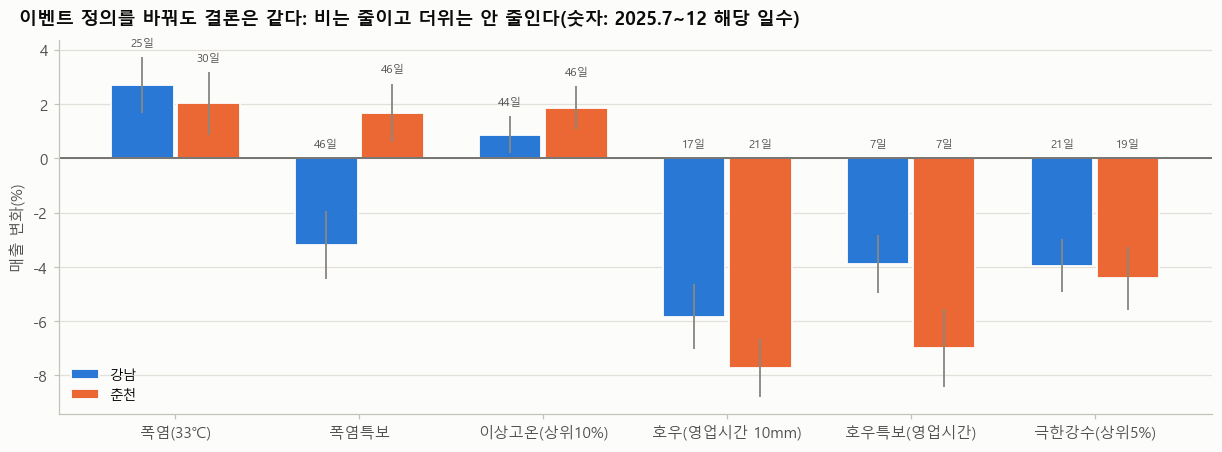

In [7]:
pick = {("기존(33℃·영업시간 10mm)", "heat_day"), ("기존(33℃·영업시간 10mm)", "rain_biz10"), ("특보 기준", "wrn_heat"), ("특보 기준", "wrn_rain_biz"),
        ("이상기후 기준(평년 상위)", "hot_extreme"), ("이상기후 기준(평년 상위)", "rain_extreme")}
show = cmp_sens[[(a, b) in pick for a, b in zip(cmp_sens["기준"], cmp_sens["var"])]].copy()
order = ["폭염(33℃)", "폭염특보", "이상고온(상위10%)", "호우(영업시간 10mm)", "호우특보(영업시간)", "극한강수(상위5%)"]
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
for i, r in enumerate(REGIONS):
    x = show[show.region == r].set_index("변수").reindex(order)
    pos = np.arange(len(order)) + (i - 0.5) * 0.36
    ax.bar(pos, x.pct, width=0.34, color=REGION_COLOR[r], label=REGION_NAME[r], edgecolor=SURFACE, linewidth=1.2)
    ax.errorbar(pos, x.pct, yerr=np.vstack([x.pct - x.lo, x.hi - x.pct]), fmt="none", ecolor=MUTED, elinewidth=1.2)
    for j, (v, n) in enumerate(zip(x.pct, x.n_days)):
        ax.text(pos[j], max(x.hi.iloc[j], 0) + 0.4, f"{n}일", ha="center", fontsize=7.5, color=INK2)
ax.axhline(0, color=INK2, lw=1); ax.set_xticks(range(len(order)), order); ax.set_ylabel("매출 변화(%)"); ax.legend(loc="lower left"); ax.grid(axis="x", visible=False)
finish(fig, FIG, "l04_sens_by_definition", "이벤트 정의를 바꿔도 결론은 같다: 비는 줄이고 더위는 안 줄인다(숫자: 2025.7~12 해당 일수)")
plt.show()

### 온열질환 응급실감시: 더위는 매출이 아니라 사람을 때린다
질병관리청 온열질환 응급실감시체계 사례(2011~2025, 감시 기간 5월 중순~9월)를 서울·강원 시도 단위로 집계해 폭염일과 맞춘다. 강원은 도 전체 환자를 춘천 기온과 맞추므로 참고 수준이다. 2018년까지는 신고 의료기관 소재지, 2019년부터는 발생 시도 기준이다.

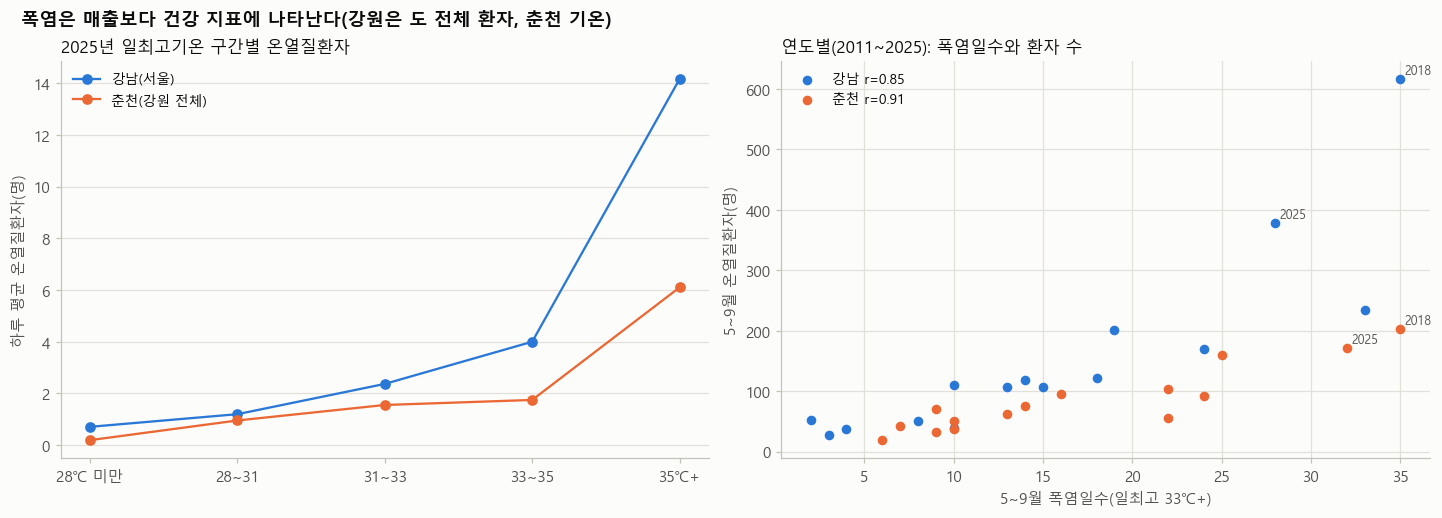

2025 폭염일 vs 아닌 날 하루 평균 환자:
heat_day  폭염 아닌 날   폭염일
지역                     
강남           1.27  8.68
춘천           0.67  3.25


지역,강남,춘천
bin,,
28℃ 미만,0.71,0.20
28~31,1.20,0.96
31~33,2.37,1.56
33~35,4.00,1.75
35℃+,14.15,6.10


In [8]:
hi = load("heat_illness_daily")
hi = hi[hi.region_sido.isin(["seoul", "gangwon"])].copy()
R_OF = {"seoul": "gangnam", "gangwon": "chuncheon"}; STN = {"gangnam": 108, "chuncheon": 101}
hi["region"] = hi.region_sido.map(R_OF)
hi = hi.groupby(["region", "date"]).cases.sum().reset_index()
# 2025년: 감시 기간(5/15~9/25) 달력에 0을 채우고 공식 일최고기온(ASOS)과 폭염일을 붙인다
rows = []
for r in REGIONS:
    cal = pd.DataFrame({"region": r, "date": pd.date_range("2025-05-15", "2025-09-25")})
    rows.append(cal)
cal25 = pd.concat(rows).merge(hi, on=["region", "date"], how="left").fillna({"cases": 0})
lt = long[long.stn.isin(STN.values())][["stn", "date", "ta_max"]].copy(); lt["region"] = lt.stn.map({v: k for k, v in STN.items()}); lt["date"] = pd.to_datetime(lt["date"])
cal25 = cal25.merge(lt[["region", "date", "ta_max"]], on=["region", "date"], how="left")
cal25["heat_day"] = (cal25.ta_max >= 33).astype(int)
cal25["bin"] = pd.cut(cal25.ta_max, [-99, 28, 31, 33, 35, 99], labels=["28℃ 미만", "28~31", "31~33", "33~35", "35℃+"])
t25 = cal25.groupby(["region", "bin"], observed=True).agg(일수=("cases", "size"), 하루_평균_환자=("cases", "mean")).reset_index()
t25["지역"] = t25.region.map(REGION_NAME)
hd = cal25.groupby(["region", "heat_day"]).cases.agg(["size", "mean", "sum"]).reset_index()
hd["지역"] = hd.region.map(REGION_NAME)
t25.round(2).to_csv(TAB / "l_heat_illness_2025.csv", index=False, encoding="utf-8-sig")
# 연도별(2011~2025): 5~9월 환자 수 vs 폭염일수
yr_cases = hi[hi.date.dt.month.between(5, 9)].assign(year=lambda d: d.date.dt.year).groupby(["region", "year"]).cases.sum().reset_index()
yr_heat = lt[lt.date.dt.month.between(5, 9) & (lt.date.dt.year >= 2011)].assign(year=lambda d: d.date.dt.year, heat=lambda d: (d.ta_max >= 33).astype(int)).groupby(["region", "year"]).heat.sum().reset_index()
yr = yr_heat.merge(yr_cases, on=["region", "year"], how="left").fillna({"cases": 0})
yr["지역"] = yr.region.map(REGION_NAME)
yr.to_csv(TAB / "l_heat_illness_yearly.csv", index=False, encoding="utf-8-sig")
corr = {r: np.corrcoef(yr[yr.region == r].heat, yr[yr.region == r].cases)[0, 1] for r in REGIONS}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
ax = axes[0]
for r in REGIONS:
    x = t25[t25.region == r]
    ax.plot(range(len(x)), x.하루_평균_환자, marker="o", color=REGION_COLOR[r], label=REGION_NAME[r] + ("(서울)" if r == "gangnam" else "(강원 전체)"))
ax.set_xticks(range(5), ["28℃ 미만", "28~31", "31~33", "33~35", "35℃+"]); ax.set_ylabel("하루 평균 온열질환자(명)"); ax.set_title("2025년 일최고기온 구간별 온열질환자"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax = axes[1]
for r in REGIONS:
    x = yr[yr.region == r]
    ax.scatter(x.heat, x.cases, color=REGION_COLOR[r], s=28, label=f"{REGION_NAME[r]} r={corr[r]:.2f}")
    for _, row in x[x.year.isin([2018, 2025])].iterrows():
        ax.annotate(int(row.year), (row.heat, row.cases), fontsize=8, color=INK2, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("5~9월 폭염일수(일최고 33℃+)"); ax.set_ylabel("5~9월 온열질환자(명)"); ax.set_title("연도별(2011~2025): 폭염일수와 환자 수"); ax.legend(frameon=False)
finish(fig, FIG, "l06_heat_illness", "폭염은 매출보다 건강 지표에 나타난다(강원은 도 전체 환자, 춘천 기온)")
plt.show()
print("2025 폭염일 vs 아닌 날 하루 평균 환자:"); print(hd.pivot(index="지역", columns="heat_day", values="mean").round(2).rename(columns={0: "폭염 아닌 날", 1: "폭염일"}))
t25.pivot(index="bin", columns="지역", values="하루_평균_환자").round(2)

## 4. 기후 시나리오: 7~12월 예상 손실(소상공인 중심 대면 업종)

30번의 시리즈별 '이벤트 하루당 손실'(2025년 실제 이벤트일 평균, 확인된 감소만)에 이벤트 일수를 곱한다. 이벤트 일수는 장기 자료의 7~12월 집계를 쓰되, 호우는 일자료에 영업시간 구분이 없어 '일 10mm+ 일수 × (2025년 영업시간 10mm+ / 일 10mm+ 비율)'로 환산한다.

시나리오: 평년(1991~2020 평균), 최근 10년(2016~2025 평균), 2025 실제, 추세 연장 2035(1991~2025 선형 추세), 폭염 +10일·호우 +5일(감도).

In [9]:
jd = ann[ann.window == "7~12월"].copy()
w = load("weather_daily").query("'2025-07-01' <= date <= '2025-12-31'")
# 장기 자료(공식 일자료)의 2025년 7~12월 이벤트 일수를 우리 정의의 2025년 실제 일수에 맞추는 환산 비율
# (호우: 영업시간 10mm+ / 일 10mm+, 열대야: 밤 최저(시간자료) / 일최저, 강남 강수는 AWS 400 / 서울 108 차이도 흡수)
LONGKEY = {"heat_day": "heat33_days", "tropical": "tropical_days", "rain_biz10": "rain10_days"}
ratio = {}
for r in REGIONS:
    ours = {"heat_day": int(w[w.region == r].heat_day.sum()), "tropical": int(w[w.region == r].tropical.sum()), "rain_biz10": int(w[w.region == r].rain_biz10.sum())}
    long25 = jd[(jd.region == r) & (jd.year == 2025)].iloc[0]
    ratio[r] = {ev: ours[ev] / max(1.0, float(long25[LONGKEY[ev]])) for ev in LONGKEY}
def days_for(region, year_sel):
    """year_sel: (시작, 끝) 연도 구간 또는 연도 표를 받아 Series를 돌려주는 함수"""
    s = jd[jd.region == region].set_index("year")
    v = year_sel(s) if callable(year_sel) else s.loc[year_sel[0]:year_sel[1], ["heat33_days", "tropical_days", "rain10_days"]].mean()
    return {ev: float(v[LONGKEY[ev]]) * ratio[region][ev] for ev in LONGKEY}
def trend_2035(s):
    out = {}
    for k in ["heat33_days", "tropical_days", "rain10_days"]:
        slope, icpt = np.polyfit(s.index, s[k].values, 1)
        out[k] = max(0.0, icpt + slope * 2035)
    return pd.Series(out)
scen = {}
for r in REGIONS:
    base = days_for(r, (2025, 2025))
    scen[(r, "평년(1991~2020)")] = days_for(r, (1991, 2020))
    scen[(r, "최근 10년(2016~25)")] = days_for(r, (2016, 2025))
    scen[(r, "2025 실제")] = base
    scen[(r, "추세 연장 2035")] = days_for(r, trend_2035)
    scen[(r, "폭염 +10일")] = {**base, "heat_day": base["heat_day"] + 10}
    scen[(r, "호우 +5일")] = {**base, "rain_biz10": base["rain_biz10"] + 5}
S = pd.DataFrame(scen).T; S.index.names = ["region", "scenario"]
face_pd = perday[(perday.face == 1) & (perday.small_biz == 1)]  # 손실 집계 범위: 소상공인 중심 대면 업종
loss_rows = []
for (r, name), days in S.iterrows():
    f = face_pd[face_pd.region == r]
    row = {"region": r, "scenario": name}
    for ev in ["heat_day", "tropical", "rain_biz10"]:
        row[f"days_{ev}"] = days[ev]
        row[f"loss_{ev}_억"] = f[f"loss_per_day_{ev}"].fillna(0).sum() * days[ev] / 1e8
    row["loss_total_억"] = sum(row[f"loss_{ev}_억"] for ev in ["heat_day", "tropical", "rain_biz10"])
    loss_rows.append(row)
L = pd.DataFrame(loss_rows)
sales6 = face_pd.groupby("region").sales_day.sum() * 184
L["손실률_%"] = L.apply(lambda x: x.loss_total_억 * 1e8 / sales6[x.region] * 100, axis=1)
L.round(2).to_csv(TAB / "l_scenario_loss.csv", index=False, encoding="utf-8-sig")
print("환산 비율(우리 2025 일수 / 공식 일자료 2025 일수):", {r: {k: round(v, 2) for k, v in d_.items()} for r, d_ in ratio.items()})
L.set_index(["region", "scenario"]).round(1)

환산 비율(우리 2025 일수 / 공식 일자료 2025 일수): {'gangnam': {'heat_day': 1.0, 'tropical': 1.02, 'rain_biz10': 0.52}, 'chuncheon': {'heat_day': 1.0, 'tropical': 1.2, 'rain_biz10': 0.81}}


days_heat_day  loss_heat_day_억  days_tropical  loss_tropical_억  days_rain_biz10  loss_rain_biz10_억  loss_total_억  손실률_%
region    scenario                                                                                                                                
gangnam   평년(1991~2020)              8.1              0.0           11.2              0.3             11.2              133.7         134.0    0.4
          최근 10년(2016~25)           18.6              0.0           25.3              0.7             10.8              129.2         130.0    0.4
          2025 실제                   25.0              0.0           45.0              1.3             17.0              203.0         204.4    0.6
          추세 연장 2035                20.8              0.0           30.5              0.9             11.5              137.6         138.5    0.4
          폭염 +10일                   35.0              0.0           45.0              1.3             17.0              203.0         204.4    0.6
          호우 +5일                    25.0              0.0           45.0              1.3             22.0              262.7         264.1    0.7
chuncheon 평년(1991~2020)              9.8              0.3            3.6              0.0             17.0               76.9          77.2    1.0
          최근 10년(2016~25)           18.8              0.6           11.0              0.0             17.5               79.3          79.9    1.1
          2025 실제                   30.0              1.0            6.0              0.0             21.0               95.1          96.0    1.3
          추세 연장 2035                20.4              0.7           13.0              0.0             19.2               87.1          87.7    1.2
          폭염 +10일                   40.0              1.3            6.0              0.0             21.0               95.1          96.4    1.3
          호우 +5일                    30.0              1.0            6.0              0.0             26.0              117.7         118.7    1.6

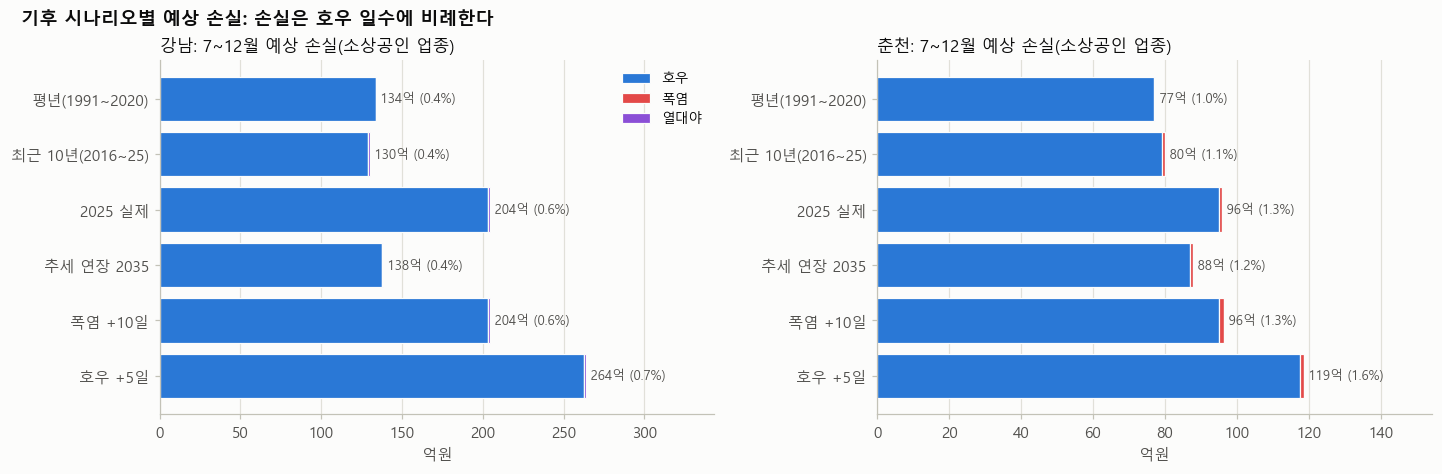

In [10]:
order = ["평년(1991~2020)", "최근 10년(2016~25)", "2025 실제", "추세 연장 2035", "폭염 +10일", "호우 +5일"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for ax, r in zip(axes, REGIONS):
    x = L[L.region == r].set_index("scenario").reindex(order)
    left = np.zeros(len(x))
    for ev, c, name in [("rain_biz10", "#2a78d6", "호우"), ("heat_day", "#e34948", "폭염"), ("tropical", "#8b4fd6", "열대야")]:
        v = x[f"loss_{ev}_억"].values
        ax.barh(range(len(x)), v, left=left, color=c, label=name, edgecolor=SURFACE, linewidth=0.8); left += v
    for i, (t, rate) in enumerate(zip(x.loss_total_억, x["손실률_%"])):
        ax.text(t, i, f" {t:.0f}억 ({rate:.1f}%)", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(range(len(x)), x.index); ax.invert_yaxis(); ax.set_title(f"{REGION_NAME[r]}: 7~12월 예상 손실(소상공인 업종)"); ax.set_xlabel("억원"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, x.loss_total_억.max() * 1.3)
axes[0].legend(loc="upper right")
finish(fig, FIG, "l05_scenario", "기후 시나리오별 예상 손실: 손실은 호우 일수에 비례한다")
plt.show()

## 요약

- `l_trend.csv`: 35년 추세. `l_context2025.csv`: 2025년 하반기의 이례성. `l_warning_overlap.csv`: 특보와 우리 기준의 겹침.
- `l_sensitivity_by_definition.csv`: 이벤트 정의(우리 기준·특보·이상기후)별 민감도. `l_scenario_loss.csv`: 시나리오 손실.

In [11]:
summary = {}
for r in REGIONS:
    t = trend[trend.region == r].set_index("지표")
    summary[REGION_NAME[r]] = {"폭염일 10년당 변화": t.loc["폭염일(일최고 33℃+)", "10년당 변화"], "폭염일 2025 순위": t.loc["폭염일(일최고 33℃+)", "2025 순위(1=최대)"],
                               "열대야 10년당 변화": t.loc["열대야(일최저 25℃+)", "10년당 변화"], "일50mm+ 10년당 변화": t.loc["일 50mm+ 일수", "10년당 변화"],
                               "강수강도 10년당 변화": t.loc["강수강도(mm/강수일)", "10년당 변화"],
                               "2025 하반기 이상고온일": summ25.loc[r, "이상고온일"],
                               "호우 민감도(특보 기준) %": cmp_sens[(cmp_sens["var"] == "wrn_rain_biz") & (cmp_sens.region == r)].pct.iloc[0],
                               "손실 평년→2025 (억)": f"{L[(L.region == r) & (L.scenario == '평년(1991~2020)')].loss_total_억.iloc[0]:.0f} → {L[(L.region == r) & (L.scenario == '2025 실제')].loss_total_억.iloc[0]:.0f}"}
pd.DataFrame(summary).round(2).to_csv(TAB / "l_summary.csv", encoding="utf-8-sig")
pd.DataFrame(summary)

,강남,춘천
폭염일 10년당 변화,4.394958,3.837535
폭염일 2025 순위,4,2
열대야 10년당 변화,6.193277,2.616246
일50mm+ 10년당 변화,0.033613,0.12605
강수강도 10년당 변화,-0.42187,0.432873
2025 하반기 이상고온일,44,46
호우 민감도(특보 기준) %,-3.888605,-7.005391
손실 평년→2025 (억),134 → 204,77 → 96
